# Perishable Product Demand Forecasting

An end-to-end workflow for estimating underlying daily demand when retail products experience stockouts, then forecasting demand for the next seven days.

This notebook documents and orchestrates the project's existing Python pipeline. The implementation is maintained in the `src/` modules; the notebook provides a reproducible, narrative walkthrough of the data, methodology, experiments, and evaluation.

> **Scope:** Daily demand forecasting only. The forecasting approaches evaluated are a Naive baseline and Ridge Regression. The earlier demand-recovery stage is a preprocessing step, not the final seven-day forecasting model.


## 1. Project objective

Observed sales can understate customer demand when a product is unavailable. The workflow therefore has two stages:

1. **Historical demand recovery:** estimate daily demand for historical store-product observations affected by stockouts.
2. **Seven-day forecasting:** use recovered historical demand and lag-based features to predict daily demand for each store-product combination over the next seven days.

The dataset does not provide independently verified lost-demand ground truth. Recovery performance is evaluated by artificially masking portions of fully in-stock observations and comparing reconstructed demand with the original observed demand. This is a methodological proxy, not proof of accuracy during real stockouts.


## 2. Environment and project setup

Run this notebook from the repository root or from the `notebooks/` directory; the first cell locates the project root automatically. The project uses `uv` to manage its Python environment.

The following cell checks the working directory and expected project files.


In [29]:
from pathlib import Path
import os
import subprocess
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

required_paths = [
    PROJECT_ROOT / "pyproject.toml",
    PROJECT_ROOT / "src" / "perishable_demand_forecasting",
    PROJECT_ROOT / "data",
]

missing = [str(path) for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Run this notebook from the project root. Missing: " + ", ".join(missing)
    )

print("Project structure checks passed.")


Project structure checks passed.


### Dependencies

Install the project dependencies from the repository root before running the notebook:

```bash
uv sync
uv add --dev ipykernel jupyter
uv run jupyter notebook
```

If Jupyter is already installed in the project environment, the second command is unnecessary.


## 3. Dataset inspection, data cleaning and exploratory analysis

The project uses the FreshRetailNet-50K dataset. The raw training data covers 2024-03-28 through 2024-06-25; the evaluation data covers 2024-06-26 through 2024-07-02.

The next cells run the existing inspection and exploratory-analysis modules. They validate the source schema, date coverage, missing values, duplicate keys, hourly arrays, sales reconciliation, and stockout patterns.


In [2]:
def run_module(module_name: str):
    """Run an existing project module with the repository's uv environment."""
    command = ["uv", "run", "python", "-m", module_name]
    print("$", " ".join(command))

    # Force UTF-8 output so Unicode characters printed by the scripts
    # are decoded correctly on Windows and other operating systems.
    env = os.environ.copy()
    env["PYTHONIOENCODING"] = "utf-8"

    result = subprocess.run(
        command,
        cwd=PROJECT_ROOT,
        text=True,
        encoding="utf-8",
        errors="replace",
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
    )
    print(result.stdout)
    if result.returncode != 0:
        raise RuntimeError(f"{module_name} failed with exit code {result.returncode}")
    return result.stdout


### What this script does

**Inputs**

Raw inputs: `data/raw/freshretailnet/data/train.parquet` and `eval.parquet`.

**Processing**

Checks schema, row counts, date/entity coverage, nulls, duplicates, hourly-array lengths, sales reconciliation, stockout reconciliation, and value ranges.

**Outputs**

No model or dataset transformation is produced; this is a quality gate before analysis.

**Why this step matters**

Confirms the raw data is structurally consistent before downstream calculations depend on it.


In [3]:
run_module("perishable_demand_forecasting.analysis.inspect_raw_dataset")

$ uv run python -m perishable_demand_forecasting.analysis.inspect_raw_dataset

TRAIN DATASET INSPECTION

1. Dataset schema
Schema({'city_id': Int64, 'store_id': Int64, 'management_group_id': Int64, 'first_category_id': Int64, 'second_category_id': Int64, 'third_category_id': Int64, 'product_id': Int64, 'dt': String, 'sale_amount': Float64, 'hours_sale': List(Float64), 'stock_hour6_22_cnt': Int32, 'hours_stock_status': List(Int64), 'discount': Float64, 'holiday_flag': Int32, 'activity_flag': Int32, 'precpt': Float64, 'avg_temperature': Float64, 'avg_humidity': Float64, 'avg_wind_level': Float64})

Rows: 4,500,000
Columns: 19

2. Date coverage
shape: (1, 3)
┌────────────┬────────────┬──────────────┐
│ start_date ┆ end_date   ┆ unique_dates │
│ ---        ┆ ---        ┆ ---          │
│ str        ┆ str        ┆ u32          │
╞════════════╪════════════╪══════════════╡
│ 2024-03-28 ┆ 2024-06-25 ┆ 90           │
└────────────┴────────────┴──────────────┘

3. Unique entities
shape: (1, 4)
┌

"\n===========================================================================\nTRAIN DATASET INSPECTION\n===========================================================================\n\n1. Dataset schema\nSchema({'city_id': Int64, 'store_id': Int64, 'management_group_id': Int64, 'first_category_id': Int64, 'second_category_id': Int64, 'third_category_id': Int64, 'product_id': Int64, 'dt': String, 'sale_amount': Float64, 'hours_sale': List(Float64), 'stock_hour6_22_cnt': Int32, 'hours_stock_status': List(Int64), 'discount': Float64, 'holiday_flag': Int32, 'activity_flag': Int32, 'precpt': Float64, 'avg_temperature': Float64, 'avg_humidity': Float64, 'avg_wind_level': Float64})\n\nRows: 4,500,000\nColumns: 19\n\n2. Date coverage\nshape: (1, 3)\n┌────────────┬────────────┬──────────────┐\n│ start_date ┆ end_date   ┆ unique_dates │\n│ ---        ┆ ---        ┆ ---          │\n│ str        ┆ str        ┆ u32          │\n╞════════════╪════════════╪══════════════╡\n│ 2024-03-28 ┆ 2024-06-25 ┆ 

### What this script does

**Inputs**

Raw hourly sales and stock-status arrays from the FreshRetailNet data.

**Processing**

Expands the hourly arrays, restricts analysis to the 06:00–21:00 operating window, and summarizes sales and stockout frequency by hour.

**Outputs**

Produces exploratory diagnostic output; it does not train a model or alter the raw data.

**Why this step matters**

Shows when demand is observed and whether stockouts are concentrated at particular hours.


In [4]:
run_module("perishable_demand_forecasting.analysis.analyze_hourly_demand_patterns")

$ uv run python -m perishable_demand_forecasting.analysis.analyze_hourly_demand_patterns

TRAIN HOURLY DEMAND PROFILE

1. Overall hourly observed-sales profile
shape: (16, 6)
┌──────┬──────────────┬───────────────────┬──────────────────┬──────────────────┬──────────────────┐
│ hour ┆ observations ┆ total_observed_sa ┆ mean_observed_sa ┆ median_observed_ ┆ zero_sales_perce │
│ ---  ┆ ---          ┆ les               ┆ les              ┆ sales            ┆ ntage            │
│ i8   ┆ u32          ┆ ---               ┆ ---              ┆ ---              ┆ ---              │
│      ┆              ┆ f64               ┆ f64              ┆ f64              ┆ f64              │
╞══════╪══════════════╪═══════════════════╪══════════════════╪══════════════════╪══════════════════╡
│ 6    ┆ 4500000      ┆ 139324.5          ┆ 0.030961         ┆ 0.0              ┆ 0.805951         │
│ 7    ┆ 4500000      ┆ 271554.7          ┆ 0.060345         ┆ 0.0              ┆ 0.677141         │
│ 8    ┆ 4500000 

'\n===========================================================================\nTRAIN HOURLY DEMAND PROFILE\n===========================================================================\n\n1. Overall hourly observed-sales profile\nshape: (16, 6)\n┌──────┬──────────────┬───────────────────┬──────────────────┬──────────────────┬──────────────────┐\n│ hour ┆ observations ┆ total_observed_sa ┆ mean_observed_sa ┆ median_observed_ ┆ zero_sales_perce │\n│ ---  ┆ ---          ┆ les               ┆ les              ┆ sales            ┆ ntage            │\n│ i8   ┆ u32          ┆ ---               ┆ ---              ┆ ---              ┆ ---              │\n│      ┆              ┆ f64               ┆ f64              ┆ f64              ┆ f64              │\n╞══════╪══════════════╪═══════════════════╪══════════════════╪══════════════════╪══════════════════╡\n│ 6    ┆ 4500000      ┆ 139324.5          ┆ 0.030961         ┆ 0.0              ┆ 0.805951         │\n│ 7    ┆ 4500000      ┆ 271554.7        

### What this script does

**Inputs**

Daily sales and stockout information from the raw dataset.

**Processing**

Groups comparable store-product observations and compares sales on stockout-affected versus fully in-stock days.

**Outputs**

Produces observational comparison statistics; it does not infer causality.

**Why this step matters**

Helps determine whether stockout-affected observations systematically differ from in-stock observations while acknowledging reverse causality.


In [5]:
run_module("perishable_demand_forecasting.analysis.analyze_matched_stockouts")

$ uv run python -m perishable_demand_forecasting.analysis.analyze_matched_stockouts

TRAIN DAILY MATCHED STOCKOUT ANALYSIS

Minimum daily observations per stock condition: 5

Matched store-product combinations: 49,777

Within-store-product daily comparison:
shape: (1, 7)
┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ matched_grou ┆ avg_daily_s ┆ avg_daily_s ┆ avg_daily_s ┆ median_dail ┆ std_daily_s ┆ percentage_ │
│ ps           ┆ ales_in_sto ┆ ales_stocko ┆ ales_differ ┆ y_sales_dif ┆ ales_differ ┆ groups_lowe │
│ ---          ┆ ck          ┆ ut          ┆ ence        ┆ ference     ┆ ence        ┆ r_during…   │
│ u32          ┆ ---         ┆ ---         ┆ ---         ┆ ---         ┆ ---         ┆ ---         │
│              ┆ f64         ┆ f64         ┆ f64         ┆ f64         ┆ f64         ┆ f64         │
╞══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ 49777        ┆ 1.06

'\n===========================================================================\nTRAIN DAILY MATCHED STOCKOUT ANALYSIS\n===========================================================================\n\nMinimum daily observations per stock condition: 5\n\nMatched store-product combinations: 49,777\n\nWithin-store-product daily comparison:\nshape: (1, 7)\n┌──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐\n│ matched_grou ┆ avg_daily_s ┆ avg_daily_s ┆ avg_daily_s ┆ median_dail ┆ std_daily_s ┆ percentage_ │\n│ ps           ┆ ales_in_sto ┆ ales_stocko ┆ ales_differ ┆ y_sales_dif ┆ ales_differ ┆ groups_lowe │\n│ ---          ┆ ck          ┆ ut          ┆ ence        ┆ ference     ┆ ence        ┆ r_during…   │\n│ u32          ┆ ---         ┆ ---         ┆ ---         ┆ ---         ┆ ---         ┆ ---         │\n│              ┆ f64         ┆ f64         ┆ f64         ┆ f64         ┆ f64         ┆ f64         │\n╞══════════════╪═════════════╪══════

### What this script does

**Inputs**

Daily stockout-hour counts and hourly stock-status/sales information.

**Processing**

Summarizes stockout severity, observed sales by severity, and hourly stockout patterns.

**Outputs**

Produces stockout diagnostics used to understand the scale and severity of availability constraints.

**Why this step matters**

Provides evidence for designing the artificial masking experiment used to evaluate demand recovery.


In [6]:
run_module("perishable_demand_forecasting.analysis.analyze_stockouts")

$ uv run python -m perishable_demand_forecasting.analysis.analyze_stockouts

Loading TRAIN: data\raw\freshretailnet\data\train.parquet

TRAIN DAILY DATA QUALITY
shape: (1, 9)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ daily_obs ┆ missing_s ┆ missing_d ┆ minimum_s ┆ … ┆ minimum_d ┆ maximum_d ┆ first_dat ┆ last_dat │
│ ervations ┆ tockout_h ┆ aily_sale ┆ tockout_h ┆   ┆ aily_sale ┆ aily_sale ┆ e         ┆ e        │
│ ---       ┆ ours      ┆ s         ┆ ours      ┆   ┆ s         ┆ s         ┆ ---       ┆ ---      │
│ u32       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ str       ┆ str      │
│           ┆ u32       ┆ u32       ┆ i32       ┆   ┆ f64       ┆ f64       ┆           ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 4500000   ┆ 0         ┆ 0         ┆ 0         ┆ … ┆ 0.0       ┆ 44.9      ┆ 2024-03-2 ┆ 2024-06- │
│           ┆    

'\nLoading TRAIN: data\\raw\\freshretailnet\\data\\train.parquet\n\n===========================================================================\nTRAIN DAILY DATA QUALITY\n===========================================================================\nshape: (1, 9)\n┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐\n│ daily_obs ┆ missing_s ┆ missing_d ┆ minimum_s ┆ … ┆ minimum_d ┆ maximum_d ┆ first_dat ┆ last_dat │\n│ ervations ┆ tockout_h ┆ aily_sale ┆ tockout_h ┆   ┆ aily_sale ┆ aily_sale ┆ e         ┆ e        │\n│ ---       ┆ ours      ┆ s         ┆ ours      ┆   ┆ s         ┆ s         ┆ ---       ┆ ---      │\n│ u32       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ str       ┆ str      │\n│           ┆ u32       ┆ u32       ┆ i32       ┆   ┆ f64       ┆ f64       ┆           ┆          │\n╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡\n│ 4500000   ┆ 0        

### Key data observations

- The source contains approximately 4.85 million daily store-product observations across 97 dates.
- Stockout-affected observations account for approximately 44.27% of training rows and 40.98% of evaluation rows.
- Fully out-of-stock observations account for approximately 4.04% of training rows and 3.58% of evaluation rows.
- Hourly sales and daily `sale_amount` reconcile within floating-point precision.
- Some sales are recorded in hours labelled out of stock, so those observations are not automatically treated as zero sales.
- Stockout patterns are observational and can be affected by reverse causality: high demand may itself contribute to stockouts.


### Data preparation and cleaning summary

The pipeline performs the following cleaning and validation steps before modelling:

- Parse `dt` as a date and enforce a 16-value hourly array for the 06:00–21:00 operating window.
- Reconcile daily `sale_amount` with the sum of `hours_sale` within floating-point tolerance.
- Check for missing values, duplicate store-product-date keys, and out-of-range stock-status values; downstream builders reject invalid hourly arrays.
- Build recovery examples from fully in-stock observations and borrow stockout masks from separate observations.
- Clip recovered daily demand to zero before lag construction, because negative demand is not physically meaningful.
- Use chronological train/validation/test splits, with a seven-day embargo between forecasting partitions to prevent temporal leakage.


## 4. Historical demand recovery

The recovery dataset is created using fully in-stock observations as reconstruction targets. Stockout masks are borrowed from other observations and applied to the hourly sales profile. The recovery model learns to estimate the original daily demand from the masked observations and associated features.

The data is split chronologically into training, validation, and test periods. The test period is held out from model selection.


### What this script does

**Inputs**

Raw observations that are fully in stock and therefore have complete observed daily sales.

**Processing**

Uses those observations as reconstruction targets and applies stockout masks borrowed from other observations to their hourly sales. It creates chronological train, validation, and test recovery datasets.

**Outputs**

Saves masked recovery examples under `data/processed/freshretailnet/recovery/`.

**Why this step matters**

Creates a controlled reconstruction problem where the original daily demand is known. This is a methodological proxy, not independently verified lost-demand ground truth.


In [7]:
run_module("perishable_demand_forecasting.recovery.build_recovery_dataset")

$ uv run python -m perishable_demand_forecasting.recovery.build_recovery_dataset
DAILY DEMAND RECOVERY DATASET PREPARATION

Target sample distribution:
Train            180,000     60.00%
Validation        60,000     20.00%
Test              60,000     20.00%
-----------------------------------
Total            300,000    100.00%
Loading dataset: data\raw\freshretailnet\data\train.parquet

Validating hourly arrays...
Hourly array lengths and stockout-hour values are valid.

TRAIN SPLIT
-----------------------------------------------------------------
Date range: 2024-04-11 to 2024-05-17
Total daily observations: 1,850,000
Fully in-stock candidate days: 1,016,466
Stockout mask donor days: 833,534
Requested synthetic samples: 180,000

Creating 180,000 synthetic daily samples...
Generated samples: 180,000
Average original daily demand: 0.930514
Average simulated observed daily sales: 0.562129
Average simulated stockout hours: 7.33
Fully masked daily samples: 18,957
Saved: data\processed\f

'===========================================================================\nDAILY DEMAND RECOVERY DATASET PREPARATION\n===========================================================================\n\nTarget sample distribution:\nTrain            180,000     60.00%\nValidation        60,000     20.00%\nTest              60,000     20.00%\n-----------------------------------\nTotal            300,000    100.00%\nLoading dataset: data\\raw\\freshretailnet\\data\\train.parquet\n\nValidating hourly arrays...\nHourly array lengths and stockout-hour values are valid.\n\nTRAIN SPLIT\n-----------------------------------------------------------------\nDate range: 2024-04-11 to 2024-05-17\nTotal daily observations: 1,850,000\nFully in-stock candidate days: 1,016,466\nStockout mask donor days: 833,534\nRequested synthetic samples: 180,000\n\nCreating 180,000 synthetic daily samples...\nGenerated samples: 180,000\nAverage original daily demand: 0.930514\nAverage simulated observed daily sales: 0.56

### What this script does

**Inputs**

The artificially masked recovery validation dataset.

**Processing**

Calculates simple reference predictions, including the observed masked sales value and a mean-based prediction, and measures their errors against the original target demand.

**Outputs**

Saves baseline recovery metrics. No learned model is trained.

**Why this step matters**

Establishes a minimum reference point that the learned recovery model must improve upon.


In [8]:
run_module("perishable_demand_forecasting.recovery.evaluate_recovery_baseline")

$ uv run python -m perishable_demand_forecasting.recovery.evaluate_recovery_baseline
DAILY DEMAND RECOVERY BASELINE EVALUATION
Loading Training dataset: data\processed\freshretailnet\recovery\train.parquet
Loading Validation dataset: data\processed\freshretailnet\recovery\validation.parquet

Training target statistics
--------------------------------------------------
Training samples: 180,000
Training mean daily demand: 0.930514

DAILY DEMAND RECOVERY BASELINE RESULTS

TRAIN RESULTS
-----------------------------------------------------------------------------------------------
shape: (2, 7)
┌────────────────┬─────────┬─────────────┬────────────────┬──────────┬──────────┬─────────────┐
│ baseline       ┆ samples ┆ actual_mean ┆ predicted_mean ┆ mae      ┆ rmse     ┆ bias        │
│ ---            ┆ ---     ┆ ---         ┆ ---            ┆ ---      ┆ ---      ┆ ---         │
│ str            ┆ i64     ┆ f64         ┆ f64            ┆ f64      ┆ f64      ┆ f64         │
╞════════════════

'===========================================================================\nDAILY DEMAND RECOVERY BASELINE EVALUATION\n===========================================================================\nLoading Training dataset: data\\processed\\freshretailnet\\recovery\\train.parquet\nLoading Validation dataset: data\\processed\\freshretailnet\\recovery\\validation.parquet\n\nTraining target statistics\n--------------------------------------------------\nTraining samples: 180,000\nTraining mean daily demand: 0.930514\n\n===============================================================================================\nDAILY DEMAND RECOVERY BASELINE RESULTS\n===============================================================================================\n\nTRAIN RESULTS\n-----------------------------------------------------------------------------------------------\nshape: (2, 7)\n┌────────────────┬─────────┬─────────────┬────────────────┬──────────┬──────────┬─────────────┐\n│ baseline       ┆

### What this script does

**Inputs**

Recovery train and validation datasets.

**Processing**

Adds calendar variables and prepares categorical, business, weather, simulated stockout, and hourly-sales information for modelling.

**Outputs**

Saves model-ready feature tables for train and validation.

**Why this step matters**

Creates a consistent feature base so later recovery experiments can be compared fairly.


In [9]:
run_module("perishable_demand_forecasting.recovery.build_recovery_features")

$ uv run python -m perishable_demand_forecasting.recovery.build_recovery_features
DAILY DEMAND RECOVERY FEATURE PREPARATION
Loading train: data\processed\freshretailnet\recovery\train.parquet

Preparing train features...
Rows: 180,000
Total columns: 48
Model features: 46
Categorical identifiers: 3

Categorical identifiers:
  - city_id
  - product_id
  - store_id

Saved: data\processed\freshretailnet\features\train.parquet
Loading validation: data\processed\freshretailnet\recovery\validation.parquet

Preparing validation features...
Rows: 60,000
Total columns: 48
Model features: 46
Categorical identifiers: 3

Categorical identifiers:
  - city_id
  - product_id
  - store_id

Saved: data\processed\freshretailnet\features\validation.parquet

FEATURE PREPARATION COMPLETE



'===========================================================================\nDAILY DEMAND RECOVERY FEATURE PREPARATION\n===========================================================================\nLoading train: data\\processed\\freshretailnet\\recovery\\train.parquet\n\nPreparing train features...\nRows: 180,000\nTotal columns: 48\nModel features: 46\nCategorical identifiers: 3\n\nCategorical identifiers:\n  - city_id\n  - product_id\n  - store_id\n\nSaved: data\\processed\\freshretailnet\\features\\train.parquet\nLoading validation: data\\processed\\freshretailnet\\recovery\\validation.parquet\n\nPreparing validation features...\nRows: 60,000\nTotal columns: 48\nModel features: 46\nCategorical identifiers: 3\n\nCategorical identifiers:\n  - city_id\n  - product_id\n  - store_id\n\nSaved: data\\processed\\freshretailnet\\features\\validation.parquet\n\n===========================================================================\nFEATURE PREPARATION COMPLETE\n==========================

### What this script does

**Inputs**

The prepared recovery feature tables.

**Processing**

Reports dimensions, target name, candidate features, data types, and missing values.

**Outputs**

Produces a feature-quality inspection report.

**Why this step matters**

Verifies that the expected modelling inputs exist before running feature experiments.


In [10]:
run_module("perishable_demand_forecasting.recovery.inspect_recovery_features")

$ uv run python -m perishable_demand_forecasting.recovery.inspect_recovery_features
DAILY DEMAND RECOVERY: FEATURE INVENTORY

Rows: 180,000
Total columns: 48

TARGET:
  target_daily_demand: Float64
  Missing values: 0

DATE:
  dt: Date

MODEL FEATURES:
---------------------------------------------------------------------------
01. city_id                                  String          nulls: 0
02. store_id                                 String          nulls: 0
03. management_group_id                      Int64           nulls: 0
04. first_category_id                        Int64           nulls: 0
05. second_category_id                       Int64           nulls: 0
06. third_category_id                        Int64           nulls: 0
07. product_id                               String          nulls: 0
08. discount                                 Float64         nulls: 0
09. holiday_flag                             Int64           nulls: 0
10. activity_flag                        

'===========================================================================\nDAILY DEMAND RECOVERY: FEATURE INVENTORY\n===========================================================================\n\nRows: 180,000\nTotal columns: 48\n\nTARGET:\n  target_daily_demand: Float64\n  Missing values: 0\n\nDATE:\n  dt: Date\n\nMODEL FEATURES:\n---------------------------------------------------------------------------\n01. city_id                                  String          nulls: 0\n02. store_id                                 String          nulls: 0\n03. management_group_id                      Int64           nulls: 0\n04. first_category_id                        Int64           nulls: 0\n05. second_category_id                       Int64           nulls: 0\n06. third_category_id                        Int64           nulls: 0\n07. product_id                               String          nulls: 0\n08. discount                                 Float64         nulls: 0\n09. holiday_flag  

### What this script does

**Inputs**

The prepared recovery feature tables.

**Processing**

Builds predefined feature groups A–H by progressively adding product, business, weather, hourly, and management information to a common core.

**Outputs**

Writes one train/validation dataset per experiment under `features/experiments/`.

**Why this step matters**

Allows feature-group performance to be compared under the same recovery modelling setup.


In [11]:
run_module("perishable_demand_forecasting.recovery.select_recovery_features")

$ uv run python -m perishable_demand_forecasting.recovery.select_recovery_features
DAILY DEMAND RECOVERY: CONTROLLED FEATURE EXPERIMENTS
Loading train: data\processed\freshretailnet\features\train.parquet
Loading validation: data\processed\freshretailnet\features\validation.parquet

EXPERIMENT: A_core
Selected features: 7

Preparing train...
Rows: 180,000
Columns: 9
Saved: data\processed\freshretailnet\features\experiments\A_core\train.parquet

Preparing validation...
Rows: 60,000
Columns: 9
Saved: data\processed\freshretailnet\features\experiments\A_core\validation.parquet

EXPERIMENT: B_product
Selected features: 10

Preparing train...
Rows: 180,000
Columns: 12
Saved: data\processed\freshretailnet\features\experiments\B_product\train.parquet

Preparing validation...
Rows: 60,000
Columns: 12
Saved: data\processed\freshretailnet\features\experiments\B_product\validation.parquet

EXPERIMENT: C_business
Selected features: 10

Preparing train...
Rows: 180,000
Columns: 12
Saved: data\proce

'===========================================================================\nDAILY DEMAND RECOVERY: CONTROLLED FEATURE EXPERIMENTS\n===========================================================================\nLoading train: data\\processed\\freshretailnet\\features\\train.parquet\nLoading validation: data\\processed\\freshretailnet\\features\\validation.parquet\n\n===========================================================================\nEXPERIMENT: A_core\n===========================================================================\nSelected features: 7\n\nPreparing train...\nRows: 180,000\nColumns: 9\nSaved: data\\processed\\freshretailnet\\features\\experiments\\A_core\\train.parquet\n\nPreparing validation...\nRows: 60,000\nColumns: 9\nSaved: data\\processed\\freshretailnet\\features\\experiments\\A_core\\validation.parquet\n\n===========================================================================\nEXPERIMENT: B_product\n=======================================================

### What this script does

**Inputs**

The A–H recovery experiment datasets.

**Processing**

For each experiment, encodes categorical identifiers, scales numerical features, trains Ridge Regression on the training partition, and evaluates it on validation data.

**Outputs**

Saves validation metrics and Ridge model artifacts; experiment G is selected based on validation performance.

**Why this step matters**

Identifies the feature configuration that provides the strongest recovery performance without using the held-out test set.


In [12]:
run_module("perishable_demand_forecasting.recovery.train_recovery_experiments")

$ uv run python -m perishable_demand_forecasting.recovery.train_recovery_experiments
DAILY DEMAND RECOVERY: CONTROLLED MODEL EXPERIMENTS

Loading baseline datasets...

VALIDATION BASELINES
Validation   MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | R2: 0.669905 | Negative predictions: 0.00%
Validation   MAE: 0.698421 | RMSE: 1.491496 | Bias: -0.120992 | R2: -0.006624 | Negative predictions: 0.00%

TRAINING EXPERIMENT: A_core
Training rows: 180,000
Validation rows: 60,000
Original features: 7
Categorical features: 3
Numerical features: 4
Ridge alpha: 1.0
Encoded features: 1,770
Train        MAE: 0.242360 | RMSE: 0.412902 | Bias: 0.000000 | R2: 0.847816 | Negative predictions: 1.32%
Validation   MAE: 0.268268 | RMSE: 0.511954 | Bias: -0.014438 | R2: 0.881400 | Negative predictions: 1.11%
Saved model: models\recovery\experiments\A_core.joblib

TRAINING EXPERIMENT: B_product
Training rows: 180,000
Validation rows: 60,000
Original features: 10
Categorical features: 6
Numerical features:

'===========================================================================\nDAILY DEMAND RECOVERY: CONTROLLED MODEL EXPERIMENTS\n===========================================================================\n\nLoading baseline datasets...\n\n===========================================================================\nVALIDATION BASELINES\n===========================================================================\nValidation   MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | R2: 0.669905 | Negative predictions: 0.00%\nValidation   MAE: 0.698421 | RMSE: 1.491496 | Bias: -0.120992 | R2: -0.006624 | Negative predictions: 0.00%\n\n===========================================================================\nTRAINING EXPERIMENT: A_core\n===========================================================================\nTraining rows: 180,000\nValidation rows: 60,000\nOriginal features: 7\nCategorical features: 3\nNumerical features: 4\nRidge alpha: 1.0\nEncoded features: 1,770\nTrain        MAE: 

### What this script does

**Inputs**

The selected recovery model and its validation predictions.

**Processing**

Groups reconstruction errors by the number of artificially masked stockout hours and compares Ridge with the observed-sales baseline.

**Outputs**

Produces severity-level MAE/RMSE/bias diagnostics.

**Why this step matters**

Shows whether recovery performance changes as the amount of missing demand information increases.


In [13]:
run_module("perishable_demand_forecasting.recovery.evaluate_recovery_by_stockout_severity")

$ uv run python -m perishable_demand_forecasting.recovery.evaluate_recovery_by_stockout_severity
DAILY DEMAND RECOVERY: STOCKOUT SEVERITY EVALUATION

Loading validation dataset...
Validation rows: 60,000

Loading trained model...

Generating model predictions...

Skipping 0 hours: no observations.

RECOVERY PERFORMANCE BY STOCKOUT SEVERITY
shape: (6, 10)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ severity  ┆ observati ┆ model_mae ┆ model_rms ┆ … ┆ baseline_ ┆ baseline_ ┆ mae_impro ┆ negative │
│ ---       ┆ ons       ┆ ---       ┆ e         ┆   ┆ rmse      ┆ bias      ┆ vement_pc ┆ _predict │
│ str       ┆ ---       ┆ f64       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ t         ┆ ion_pct  │
│           ┆ i64       ┆           ┆ f64       ┆   ┆ f64       ┆ f64       ┆ ---       ┆ ---      │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪

'===========================================================================\nDAILY DEMAND RECOVERY: STOCKOUT SEVERITY EVALUATION\n===========================================================================\n\nLoading validation dataset...\nValidation rows: 60,000\n\nLoading trained model...\n\nGenerating model predictions...\n\nSkipping 0 hours: no observations.\n\n===========================================================================\nRECOVERY PERFORMANCE BY STOCKOUT SEVERITY\n===========================================================================\nshape: (6, 10)\n┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐\n│ severity  ┆ observati ┆ model_mae ┆ model_rms ┆ … ┆ baseline_ ┆ baseline_ ┆ mae_impro ┆ negative │\n│ ---       ┆ ons       ┆ ---       ┆ e         ┆   ┆ rmse      ┆ bias      ┆ vement_pc ┆ _predict │\n│ str       ┆ ---       ┆ f64       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ t         ┆ ion_pct  │\n│         

### What this script does

**Inputs**

Recovery experiment G plus its train/validation data.

**Processing**

Trains Ridge models using several predefined `alpha` values and compares validation MAE, RMSE, bias, and negative-prediction rate.

**Outputs**

Saves regularization metrics and candidate model artifacts.

**Why this step matters**

Tests whether regularization materially improves the selected recovery model before freezing the configuration.


In [14]:
run_module("perishable_demand_forecasting.recovery.tune_recovery_ridge")

$ uv run python -m perishable_demand_forecasting.recovery.tune_recovery_ridge
DAILY DEMAND RECOVERY: RIDGE REGULARIZATION EXPERIMENTS

Loading datasets...

Training rows: 180,000
Validation rows: 60,000
Original features: 26
Categorical features: 3
Numerical features: 23
Alpha values: [0.01, 0.1, 1.0, 10.0, 100.0]

VALIDATION BASELINES
Validation   MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | R2: 0.669905 | Negative predictions: 0.00%
Validation   MAE: 0.698421 | RMSE: 1.491496 | Bias: -0.120992 | R2: -0.006624 | Negative predictions: 0.00%

RIDGE REGULARIZATION: ALPHA = 0.01
Train        MAE: 0.238719 | RMSE: 0.396251 | Bias: 0.000000 | R2: 0.859843 | Negative predictions: 1.56%
Validation   MAE: 0.262977 | RMSE: 0.478853 | Bias: -0.011295 | R2: 0.896240 | Negative predictions: 1.42%
Encoded features: 1,789
Saved model: models\recovery\regularization\G_business_hourly_alpha_0.01.joblib

RIDGE REGULARIZATION: ALPHA = 0.1
Train        MAE: 0.238672 | RMSE: 0.396251 | Bias: 0.00000

'===========================================================================\nDAILY DEMAND RECOVERY: RIDGE REGULARIZATION EXPERIMENTS\n===========================================================================\n\nLoading datasets...\n\nTraining rows: 180,000\nValidation rows: 60,000\nOriginal features: 26\nCategorical features: 3\nNumerical features: 23\nAlpha values: [0.01, 0.1, 1.0, 10.0, 100.0]\n\n===========================================================================\nVALIDATION BASELINES\n===========================================================================\nValidation   MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | R2: 0.669905 | Negative predictions: 0.00%\nValidation   MAE: 0.698421 | RMSE: 1.491496 | Bias: -0.120992 | R2: -0.006624 | Negative predictions: 0.00%\n\n===========================================================================\nRIDGE REGULARIZATION: ALPHA = 0.01\n===========================================================================\nTrain     

### What this script does

**Inputs**

The recovery validation predictions from Ridge alpha 1 and alpha 10.

**Processing**

Compares the two regularization settings with the observed-sales baseline separately across stockout-severity groups.

**Outputs**

Produces severity-level comparisons for the candidate recovery configurations.

**Why this step matters**

Checks whether a regularization choice behaves differently for lightly versus heavily masked observations.


In [15]:
run_module("perishable_demand_forecasting.recovery.evaluate_tuned_ridge_by_severity")

$ uv run python -m perishable_demand_forecasting.recovery.evaluate_tuned_ridge_by_severity
DAILY DEMAND RECOVERY: RIDGE SEVERITY EVALUATION

Loading validation data...
Validation rows: 60,000

Loading Ridge models...

Generating predictions...

OVERALL VALIDATION RESULTS
observed_sales_baselineRows:  60,000 | MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | Negative: 0.00%
ridge_alpha_1         Rows:  60,000 | MAE: 0.262156 | RMSE: 0.479490 | Bias: -0.011003 | Negative: 1.39%
ridge_alpha_10        Rows:  60,000 | MAE: 0.258711 | RMSE: 0.488609 | Bias: -0.008614 | Negative: 1.27%

---------------------------------------------------------------------------
STOCKOUT SEVERITY: 1-2 hours (9,049 rows)
---------------------------------------------------------------------------
observed_sales_baselineRows:   9,049 | MAE: 0.049380 | RMSE: 0.146814 | Bias: -0.049380 | Negative: 0.00%
ridge_alpha_1         Rows:   9,049 | MAE: 0.211789 | RMSE: 0.315708 | Bias: -0.029075 | Negative: 4.42%
ridge_

'===========================================================================\nDAILY DEMAND RECOVERY: RIDGE SEVERITY EVALUATION\n===========================================================================\n\nLoading validation data...\nValidation rows: 60,000\n\nLoading Ridge models...\n\nGenerating predictions...\n\n===========================================================================\nOVERALL VALIDATION RESULTS\n===========================================================================\nobserved_sales_baselineRows:  60,000 | MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | Negative: 0.00%\nridge_alpha_1         Rows:  60,000 | MAE: 0.262156 | RMSE: 0.479490 | Bias: -0.011003 | Negative: 1.39%\nridge_alpha_10        Rows:  60,000 | MAE: 0.258711 | RMSE: 0.488609 | Bias: -0.008614 | Negative: 1.27%\n\n---------------------------------------------------------------------------\nSTOCKOUT SEVERITY: 1-2 hours (9,049 rows)\n-----------------------------------------------------------

### What this script does

**Inputs**

Validation predictions from the observed-sales baseline, Ridge alpha 1, and Ridge alpha 10.

**Processing**

Applies a fixed severity-based routing rule: observed sales for 1–5 stockout hours, Ridge alpha 10 for 6–9 hours, and Ridge alpha 1 for 10–16 hours.

**Outputs**

Reports overall and severity-level validation performance for the hybrid and its component models.

**Why this step matters**

Tests whether combining methods according to known historical stockout severity improves reconstruction accuracy.


In [16]:
run_module("perishable_demand_forecasting.recovery.evaluate_hybrid_strategies")

$ uv run python -m perishable_demand_forecasting.recovery.evaluate_hybrid_strategies
DAILY DEMAND RECOVERY: HYBRID STRATEGY EVALUATION

Loading validation data...
Validation rows: 60,000

Loading trained models...

Generating predictions...

Creating hybrid predictions...

OVERALL VALIDATION COMPARISON
observed_sales_baseline  MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | Negative: 0.00%
ridge_alpha_1            MAE: 0.262156 | RMSE: 0.479490 | Bias: -0.011003 | Negative: 1.39%
ridge_alpha_10           MAE: 0.258711 | RMSE: 0.488609 | Bias: -0.008614 | Negative: 1.27%
hybrid_recovery          MAE: 0.228195 | RMSE: 0.481077 | Bias: -0.074179 | Negative: 0.16%

VALIDATION RESULTS BY STOCKOUT SEVERITY

1-2 hours (9,049 rows)
observed_sales_baseline  MAE: 0.049380 | RMSE: 0.146814 | Bias: -0.049380 | Negative: 0.00%
ridge_alpha_1            MAE: 0.211789 | RMSE: 0.315708 | Bias: -0.029075 | Negative: 4.42%
ridge_alpha_10           MAE: 0.203050 | RMSE: 0.297307 | Bias: -0.026584 | Neg

'===========================================================================\nDAILY DEMAND RECOVERY: HYBRID STRATEGY EVALUATION\n===========================================================================\n\nLoading validation data...\nValidation rows: 60,000\n\nLoading trained models...\n\nGenerating predictions...\n\nCreating hybrid predictions...\n\n===========================================================================\nOVERALL VALIDATION COMPARISON\n===========================================================================\nobserved_sales_baseline  MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | Negative: 0.00%\nridge_alpha_1            MAE: 0.262156 | RMSE: 0.479490 | Bias: -0.011003 | Negative: 1.39%\nridge_alpha_10           MAE: 0.258711 | RMSE: 0.488609 | Bias: -0.008614 | Negative: 1.27%\nhybrid_recovery          MAE: 0.228195 | RMSE: 0.481077 | Bias: -0.074179 | Negative: 0.16%\n\n===========================================================================\nVALIDATIO

### What this script does

**Inputs**

The frozen hybrid strategy plus several alternative fixed routing strategies.

**Processing**

Compares a small predefined set of routing combinations without searching endlessly for thresholds.

**Outputs**

Produces validation metrics for each routing strategy and identifies the frozen hybrid.

**Why this step matters**

Checks whether the chosen recovery rule is reasonably stable rather than depending on one arbitrary Ridge assignment.


In [17]:
run_module("perishable_demand_forecasting.recovery.test_hybrid_robustness")

$ uv run python -m perishable_demand_forecasting.recovery.test_hybrid_robustness
DAILY DEMAND RECOVERY: HYBRID ROBUSTNESS EXPERIMENT

Loading validation data...
Validation rows: 60,000

Loading trained models...

Generating model predictions...

Evaluating hybrid strategies...

OVERALL VALIDATION COMPARISON
observed_sales_baseline MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | Negative: 0.00%
ridge_alpha_1           MAE: 0.262156 | RMSE: 0.479490 | Bias: -0.011003 | Negative: 1.39%
ridge_alpha_10          MAE: 0.258711 | RMSE: 0.488609 | Bias: -0.008614 | Negative: 1.27%
current_hybrid          MAE: 0.228195 | RMSE: 0.481077 | Bias: -0.074179 | Negative: 0.16%
alternative_a           MAE: 0.229350 | RMSE: 0.481245 | Bias: -0.074997 | Negative: 0.21%
alternative_b           MAE: 0.229992 | RMSE: 0.495189 | Bias: -0.074245 | Negative: 0.15%
alternative_c           MAE: 0.231147 | RMSE: 0.495352 | Bias: -0.075063 | Negative: 0.19%

VALIDATION RESULTS BY STOCKOUT SEVERITY

1-2 hours (9

'=====================================================================================\nDAILY DEMAND RECOVERY: HYBRID ROBUSTNESS EXPERIMENT\n=====================================================================================\n\nLoading validation data...\nValidation rows: 60,000\n\nLoading trained models...\n\nGenerating model predictions...\n\nEvaluating hybrid strategies...\n\n=====================================================================================\nOVERALL VALIDATION COMPARISON\n=====================================================================================\nobserved_sales_baseline MAE: 0.376523 | RMSE: 0.854098 | Bias: -0.376523 | Negative: 0.00%\nridge_alpha_1           MAE: 0.262156 | RMSE: 0.479490 | Bias: -0.011003 | Negative: 1.39%\nridge_alpha_10          MAE: 0.258711 | RMSE: 0.488609 | Bias: -0.008614 | Negative: 1.27%\ncurrent_hybrid          MAE: 0.228195 | RMSE: 0.481077 | Bias: -0.074179 | Negative: 0.16%\nalternative_a           MAE: 0.229350 | RMS

### What this script does

**Inputs**

The untouched artificial-mask recovery test set and the frozen recovery strategy.

**Processing**

Applies the frozen hybrid without changing its rules, then measures reconstruction error overall and by stockout severity.

**Outputs**

Produces the final recovery test metrics.

**Why this step matters**

Provides the held-out evaluation of the recovery stage while preserving the limitation that the target comes from artificial masking.


In [18]:
run_module("perishable_demand_forecasting.recovery.evaluate_hybrid_on_test")

$ uv run python -m perishable_demand_forecasting.recovery.evaluate_hybrid_on_test
DAILY DEMAND RECOVERY: FINAL TEST EVALUATION

Loading untouched test dataset...
Test rows: 60,000

Preparing test features...

Loading trained Ridge models...

Generating predictions...

Evaluating test predictions...

OVERALL TEST COMPARISON
               strategy  rows      MAE     RMSE      Bias Negative_predictions_pct
observed_sales_baseline 60000 0.418767 0.977165 -0.418767                    0.00%
          ridge_alpha_1 60000 0.292391 0.573632 -0.049829                    1.29%
         ridge_alpha_10 60000 0.287649 0.584411 -0.043188                    1.16%
          frozen_hybrid 60000 0.259736 0.587402 -0.104111                    0.10%

TEST RESULTS BY STOCKOUT SEVERITY

1-2 hours
 severity  rows                strategy      MAE     RMSE      Bias Negative_predictions_pct
1-2 hours  8170 observed_sales_baseline 0.055950 0.148431 -0.055950                    0.00%
1-2 hours  8170           ri

'=====================================================================================\nDAILY DEMAND RECOVERY: FINAL TEST EVALUATION\n=====================================================================================\n\nLoading untouched test dataset...\nTest rows: 60,000\n\nPreparing test features...\n\nLoading trained Ridge models...\n\nGenerating predictions...\n\nEvaluating test predictions...\n\n=====================================================================================\nOVERALL TEST COMPARISON\n=====================================================================================\n               strategy  rows      MAE     RMSE      Bias Negative_predictions_pct\nobserved_sales_baseline 60000 0.418767 0.977165 -0.418767                    0.00%\n          ridge_alpha_1 60000 0.292391 0.573632 -0.049829                    1.29%\n         ridge_alpha_10 60000 0.287649 0.584411 -0.043188                    1.16%\n          frozen_hybrid 60000 0.259736 0.587402 -0.104111 

### Recovery model selection and test results

The selected recovery approach is a frozen hybrid strategy:

- 0–5 stockout hours: use observed daily sales.
- 6–9 stockout hours: use Ridge Regression with alpha 10.
- 10–16 stockout hours: use Ridge Regression with alpha 1.

The untouched artificial-mask test evaluation produced:

| Method | MAE | RMSE |
|---|---:|---:|
| Observed-sales baseline | 0.418767 | 0.977165 |
| Frozen hybrid recovery | **0.259736** | **0.587402** |

The hybrid reduced MAE by approximately 38.0% relative to the observed-sales baseline on this artificial-mask test. This result should be interpreted within the reconstruction experiment and not as independently verified real-stockout accuracy.

Negative recovery predictions are clipped to zero in the historical preprocessing pipeline. The underlying saved Ridge models are not modified.


## 5. Prepare the seven-day forecasting dataset

The forecasting dataset is built from the recovered daily demand history. It includes:

- Demand lags 1–14.
- Seven-day and fourteen-day rolling mean demand.
- Lagged stockout information.
- Forecast horizon (days 1–7).
- Future-known calendar metadata such as weekday, month, and holiday flag.

The data is split chronologically into training, validation, and test partitions, with a seven-day embargo between partitions to reduce temporal leakage.


### What this script does

**Inputs**

Raw historical train/eval observations plus the frozen recovery Ridge models.

**Processing**

Recovers historical daily demand using the frozen hybrid, builds demand lags 1–14, rolling means, lagged stockout indicators, and seven forecast horizons, then performs chronological splitting with a seven-day embargo.

**Outputs**

Saves `recovered_daily_demand.parquet`, `train.parquet`, `validation.parquet`, and `test.parquet` under `forecasting/`.

**Why this step matters**

Transforms the recovered historical series into the supervised dataset required by the final seven-day forecasting models.


In [19]:
run_module("perishable_demand_forecasting.data.build_daily_forecast_dataset")

$ uv run python -m perishable_demand_forecasting.data.build_daily_forecast_dataset
PERISHABLE PRODUCT DEMAND FORECASTING
DAILY 7-DAY FORECAST DATA PREPARATION
Polars thread pool size: 8
Loading source datasets...
Loading frozen recovery models...

RECOVERING HISTORICAL DAILY DEMAND
Extracting hourly observations...
Source observations: 4,850,000
Clipped 20 negative demand predictions to zero.
Clipped 13 negative demand predictions to zero.
Clipped 5 negative demand predictions to zero.
Clipped 1 negative demand predictions to zero.
Clipped 22 negative demand predictions to zero.
Clipped 12 negative demand predictions to zero.
Clipped 17 negative demand predictions to zero.
Clipped 4 negative demand predictions to zero.
Clipped 8 negative demand predictions to zero.
Clipped 4 negative demand predictions to zero.
Processed 10/97 dates
Clipped 7 negative demand predictions to zero.
Clipped 18 negative demand predictions to zero.
Clipped 19 negative demand predictions to zero.
Clipped 9 ne

'=================================================================\nPERISHABLE PRODUCT DEMAND FORECASTING\nDAILY 7-DAY FORECAST DATA PREPARATION\n=================================================================\nPolars thread pool size: 8\nLoading source datasets...\nLoading frozen recovery models...\n\n=================================================================\nRECOVERING HISTORICAL DAILY DEMAND\n=================================================================\nExtracting hourly observations...\nSource observations: 4,850,000\nClipped 20 negative demand predictions to zero.\nClipped 13 negative demand predictions to zero.\nClipped 5 negative demand predictions to zero.\nClipped 1 negative demand predictions to zero.\nClipped 22 negative demand predictions to zero.\nClipped 12 negative demand predictions to zero.\nClipped 17 negative demand predictions to zero.\nClipped 4 negative demand predictions to zero.\nClipped 8 negative demand predictions to zero.\nClipped 4 negative d

### Forecasting dataset summary

The successful dataset preparation produced:

| Partition | Forecast origins | Rows |
|---|---:|---:|
| Training | 37 | 12,950,000 |
| Validation | 13 | 4,550,000 |
| Test | 12 | 4,200,000 |

The forecast target is recovered daily demand. The recovery stage is historical preprocessing; it is not the seven-day forecasting model.


### Target variable analysis

The forecasting target is recovered daily demand. The summary checks its range, central tendency, tail and zero share across the chronological splits; the histogram uses the training split.


     split     rows  min  median     mean      p99       max  zero_pct
     train 12950000  0.0     0.8 1.143325 6.300000 35.743503  1.007676
validation  4550000  0.0     0.8 1.144600 5.994347 40.406449  1.005802
      test  4200000  0.0     0.9 1.302908 7.100000 49.900000  1.068762


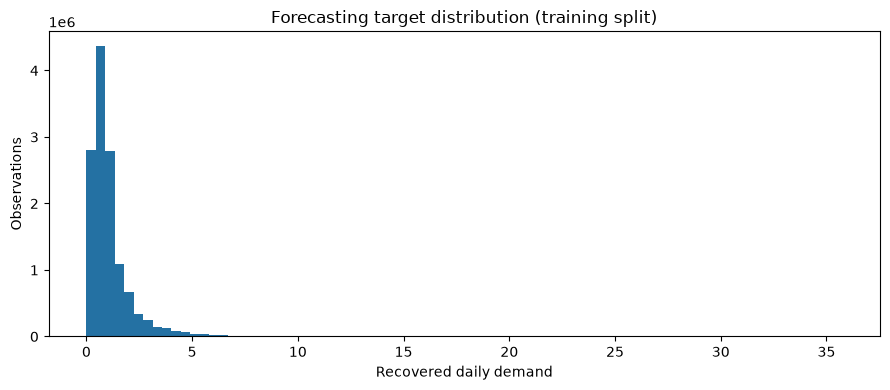

In [20]:
import matplotlib.pyplot as plt
import polars as pl

from perishable_demand_forecasting.config import FORECASTING_DIR

summary_rows = []
for split in ["train", "validation", "test"]:
    target = (
        pl.scan_parquet(FORECASTING_DIR / f"{split}.parquet")
        .select(pl.col("target_daily_demand"))
        .collect()
        .get_column("target_daily_demand")
    )
    summary_rows.append(
        {
            "split": split,
            "rows": target.len(),
            "min": target.min(),
            "median": target.median(),
            "mean": target.mean(),
            "p99": target.quantile(0.99),
            "max": target.max(),
            "zero_pct": (target == 0).mean() * 100,
        }
    )

print(pl.DataFrame(summary_rows).to_pandas().to_string(index=False))

train_target = (
    pl.scan_parquet(FORECASTING_DIR / "train.parquet")
    .select(pl.col("target_daily_demand"))
    .collect()
    .get_column("target_daily_demand")
    .to_numpy()
)

plt.figure(figsize=(9, 4))
plt.hist(train_target, bins=80, color="#2471a3")
plt.xlabel("Recovered daily demand")
plt.ylabel("Observations")
plt.title("Forecasting target distribution (training split)")
plt.tight_layout()
plt.show()


## 6. Naive forecasting baseline

The Naive baseline predicts each horizon using the most recent available recovered daily demand (`demand_lag_1`). It is rule-based and therefore has no model-training step.

The evaluation reports MAE, RMSE, and bias overall and separately for each forecast horizon.


### What this script does

**Inputs**

The forecasting validation dataset.

**Processing**

Uses `demand_lag_1` as the prediction for every forecast horizon, with no training step. It calculates MAE, RMSE, and bias overall and for days 1–7.

**Outputs**

Saves Naive validation metrics.

**Why this step matters**

Provides the simple baseline that Ridge must beat to demonstrate useful predictive value.


In [21]:
run_module("perishable_demand_forecasting.forecasting.evaluate_naive_forecast")

$ uv run python -m perishable_demand_forecasting.forecasting.evaluate_naive_forecast
NAIVE FORECAST: VALIDATION EVALUATION

Loading validation dataset: data\processed\freshretailnet\forecasting\validation.parquet

OVERALL NAIVE FORECAST RESULTS
shape: (1, 6)
┌──────────────────┬──────────────────┬──────────────┬─────────┬──────────┬──────────┐
│ evaluation_scope ┆ forecast_horizon ┆ observations ┆ mae     ┆ rmse     ┆ bias     │
│ ---              ┆ ---              ┆ ---          ┆ ---     ┆ ---      ┆ ---      │
│ str              ┆ i64              ┆ u32          ┆ f64     ┆ f64      ┆ f64      │
╞══════════════════╪══════════════════╪══════════════╪═════════╪══════════╪══════════╡
│ overall          ┆ null             ┆ 4550000      ┆ 0.47762 ┆ 0.803075 ┆ 0.020007 │
└──────────────────┴──────────────────┴──────────────┴─────────┴──────────┴──────────┘

NAIVE FORECAST RESULTS BY HORIZON
shape: (7, 6)
┌──────────────────┬──────────────────┬──────────────┬──────────┬──────────┬───────

'===========================================================================\nNAIVE FORECAST: VALIDATION EVALUATION\n===========================================================================\n\nLoading validation dataset: data\\processed\\freshretailnet\\forecasting\\validation.parquet\n\n===========================================================================\nOVERALL NAIVE FORECAST RESULTS\n===========================================================================\nshape: (1, 6)\n┌──────────────────┬──────────────────┬──────────────┬─────────┬──────────┬──────────┐\n│ evaluation_scope ┆ forecast_horizon ┆ observations ┆ mae     ┆ rmse     ┆ bias     │\n│ ---              ┆ ---              ┆ ---          ┆ ---     ┆ ---      ┆ ---      │\n│ str              ┆ i64              ┆ u32          ┆ f64     ┆ f64      ┆ f64      │\n╞══════════════════╪══════════════════╪══════════════╪═════════╪══════════╪══════════╡\n│ overall          ┆ null             ┆ 4550000      ┆ 0.47762 ┆ 0.

### Naive validation results

| Metric | Validation |
|---|---:|
| MAE | 0.477620 |
| RMSE | 0.803075 |
| Bias | +0.020007 |



## 7. Linear forecasting model (Ridge)

Ridge Regression is the linear baseline. It is trained using the training partition. Feature scaling is fitted on training data only and then applied to validation data. The selected feature set includes demand lags, rolling statistics, lagged stockout information, forecast horizon, and future-known calendar fields.

The initial configuration uses `alpha=1.0`. The model artifact stores the fitted scaler, estimator, feature list, target name, and alpha.


### What this script does

**Inputs**

Forecasting train and validation datasets.

**Processing**

Selects the 22 forecasting features, fits `StandardScaler` only on training data, trains Ridge Regression with alpha 1.0, and evaluates validation predictions.

**Outputs**

Saves the Ridge model, scaler, feature metadata, and validation metrics.

**Why this step matters**

Creates the main machine-learning forecasting model while preventing validation information from influencing feature scaling.


In [22]:
run_module("perishable_demand_forecasting.forecasting.train_ridge_forecast")

$ uv run python -m perishable_demand_forecasting.forecasting.train_ridge_forecast
RIDGE REGRESSION: 7-DAY DEMAND FORECASTING

Forecast features:
  - demand_lag_1
  - demand_lag_2
  - demand_lag_3
  - demand_lag_4
  - demand_lag_5
  - demand_lag_6
  - demand_lag_7
  - demand_lag_8
  - demand_lag_9
  - demand_lag_10
  - demand_lag_11
  - demand_lag_12
  - demand_lag_13
  - demand_lag_14
  - demand_rolling_mean_7
  - demand_rolling_mean_14
  - stockout_hours_lag_1
  - stockout_hours_lag_7
  - forecast_horizon
  - target_weekday
  - target_month
  - target_holiday_flag

Loading training dataset...
Training rows: 12,950,000

Standardizing features...

Training Ridge Regression (alpha=1.0)...
Ridge Regression training complete.

Model saved to: models\forecasting\ridge_forecast.joblib

Loading validation dataset...
Validation rows: 4,550,000

Generating validation predictions...

Evaluating validation predictions...

OVERALL RIDGE FORECAST RESULTS
shape: (1, 7)
┌────────────────┬────────────

'===========================================================================\nRIDGE REGRESSION: 7-DAY DEMAND FORECASTING\n===========================================================================\n\nForecast features:\n  - demand_lag_1\n  - demand_lag_2\n  - demand_lag_3\n  - demand_lag_4\n  - demand_lag_5\n  - demand_lag_6\n  - demand_lag_7\n  - demand_lag_8\n  - demand_lag_9\n  - demand_lag_10\n  - demand_lag_11\n  - demand_lag_12\n  - demand_lag_13\n  - demand_lag_14\n  - demand_rolling_mean_7\n  - demand_rolling_mean_14\n  - stockout_hours_lag_1\n  - stockout_hours_lag_7\n  - forecast_horizon\n  - target_weekday\n  - target_month\n  - target_holiday_flag\n\nLoading training dataset...\nTraining rows: 12,950,000\n\nStandardizing features...\n\nTraining Ridge Regression (alpha=1.0)...\nRidge Regression training complete.\n\nModel saved to: models\\forecasting\\ridge_forecast.joblib\n\nLoading validation dataset...\nValidation rows: 4,550,000\n\nGenerating validation predictions...\

### Ridge regularization experiment

Several alpha values were evaluated on the validation partition. The displayed metrics were effectively indistinguishable at the reported precision:

| Alpha | MAE | RMSE |
|---:|---:|---:|
| 0.01 | 0.374763 | 0.604713 |
| 0.1 | 0.374763 | 0.604713 |
| 1 | 0.374763 | 0.604713 |
| 10 | 0.374763 | 0.604713 |
| 100 | 0.374763 | 0.604713 |

No meaningful practical improvement was demonstrated by increasing alpha. The project therefore retains the original `alpha=1.0` model for the final test evaluation rather than selecting a value based on negligible metric differences.


### What this script does

**Inputs**

The same forecasting train/validation partitions used for the initial Ridge model.

**Processing**

Evaluates Ridge across predefined alpha values using the same features and training-only scaler.

**Outputs**

Saves alpha comparison metrics and a tuned candidate artifact.

**Why this step matters**

Checks whether changing regularization produces a meaningful validation improvement; the differences were negligible, so alpha 1 remains the selected final configuration.


In [23]:
run_module("perishable_demand_forecasting.forecasting.tune_ridge_forecast")

$ uv run python -m perishable_demand_forecasting.forecasting.tune_ridge_forecast
RIDGE REGRESSION: REGULARIZATION TUNING

Loading training dataset...
Training rows: 12,950,000

Loading validation dataset...
Validation rows: 4,550,000

Standardizing features...

---------------------------------------------------------------------------
Training Ridge Regression with alpha=0.01
---------------------------------------------------------------------------
MAE:                     0.374763
RMSE:                    0.604713
Bias:                    0.001554
Negative predictions:    0.0294%

---------------------------------------------------------------------------
Training Ridge Regression with alpha=0.1
---------------------------------------------------------------------------
MAE:                     0.374763
RMSE:                    0.604713
Bias:                    0.001554
Negative predictions:    0.0294%

---------------------------------------------------------------------------
Tra

'===========================================================================\nRIDGE REGRESSION: REGULARIZATION TUNING\n===========================================================================\n\nLoading training dataset...\nTraining rows: 12,950,000\n\nLoading validation dataset...\nValidation rows: 4,550,000\n\nStandardizing features...\n\n---------------------------------------------------------------------------\nTraining Ridge Regression with alpha=0.01\n---------------------------------------------------------------------------\nMAE:                     0.374763\nRMSE:                    0.604713\nBias:                    0.001554\nNegative predictions:    0.0294%\n\n---------------------------------------------------------------------------\nTraining Ridge Regression with alpha=0.1\n---------------------------------------------------------------------------\nMAE:                     0.374763\nRMSE:                    0.604713\nBias:                    0.001554\nNegative predic

### Feature importance analysis

The final model is a Random Forest, so its built-in `feature_importances_` (impurity-based) are used. If a linear artifact is loaded instead, the absolute standardized Ridge coefficients are shown. The final model is retrained on the train+validation partitions by `train.py`; the notebook uses that artifact.


Using model: final_demand_forecast.pkl (random_forest)

Feature importance (sorted by absolute value):
               feature  importance  absolute_value    feature_group
demand_rolling_mean_14    0.436349        0.436349   Rolling demand
 demand_rolling_mean_7    0.280963        0.280963   Rolling demand
          demand_lag_6    0.071171        0.071171      Demand lags
          demand_lag_1    0.067793        0.067793      Demand lags
          demand_lag_2    0.040610        0.040610      Demand lags
          demand_lag_3    0.022313        0.022313      Demand lags
        target_weekday    0.019945        0.019945         Calendar
          demand_lag_5    0.019177        0.019177      Demand lags
          demand_lag_4    0.012548        0.012548      Demand lags
   target_holiday_flag    0.010636        0.010636         Calendar
          target_month    0.002167        0.002167         Calendar
         demand_lag_10    0.002046        0.002046      Demand lags
          dem

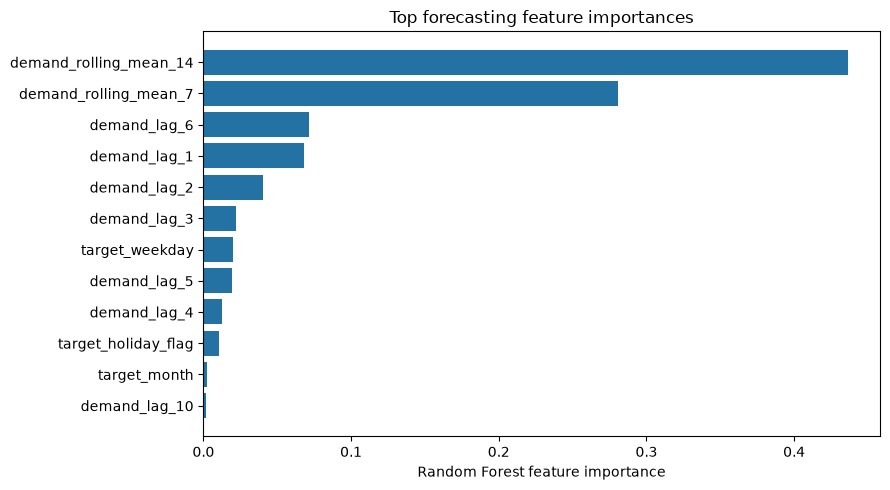

In [24]:
import joblib
import pickle
import matplotlib.pyplot as plt
import polars as pl

from perishable_demand_forecasting.config import FORECASTING_MODELS_DIR

model_candidates = [
    FORECASTING_MODELS_DIR / "final_demand_forecast.pkl",
    FORECASTING_MODELS_DIR / "tree_forecast_tuned.pkl",
    FORECASTING_MODELS_DIR / "ridge_forecast.joblib",
]
model_path = next((path for path in model_candidates if path.exists()), None)
if model_path is None:
    raise FileNotFoundError(
        "No trained model found. Run `uv run python train.py` first."
    )

if model_path.suffix == ".pkl":
    with model_path.open("rb") as file:
        bundle = pickle.load(file)
else:
    bundle = joblib.load(model_path)

print(f"Using model: {model_path.name} ({bundle.get('family', 'ridge_regression')})")

model = bundle["model"]
if hasattr(model, "feature_importances_"):
    values = model.feature_importances_
    value_label = "importance"
    value_title = "Random Forest feature importance"
else:
    values = model.coef_
    value_label = "coefficient"
    value_title = "Standardized Ridge coefficient"

importance = (
    pl.DataFrame({"feature": bundle["features"], value_label: values})
    .with_columns(
        pl.col(value_label).abs().alias("absolute_value"),
        pl.when(pl.col("feature").str.starts_with("demand_lag_"))
        .then(pl.lit("Demand lags"))
        .when(pl.col("feature").str.starts_with("demand_rolling"))
        .then(pl.lit("Rolling demand"))
        .when(pl.col("feature").str.starts_with("stockout_hours"))
        .then(pl.lit("Stockout history"))
        .when(pl.col("feature") == "forecast_horizon")
        .then(pl.lit("Forecast horizon"))
        .otherwise(pl.lit("Calendar"))
        .alias("feature_group"),
    )
    .sort("absolute_value", descending=True)
)

print()
print("Feature importance (sorted by absolute value):")
print(importance.to_pandas().to_string(index=False))

group_importance = (
    importance.group_by("feature_group")
    .agg(pl.col("absolute_value").sum().alias("total_absolute_value"))
    .with_columns(
        (pl.col("total_absolute_value") / pl.col("total_absolute_value").sum() * 100)
        .round(2)
        .alias("share_pct")
    )
    .sort("total_absolute_value", descending=True)
)

print()
print("Aggregated importance by feature group:")
print(group_importance.to_pandas().to_string(index=False))

top = importance.head(12).sort(value_label)
colors = (
    ["#2471a3"] * top.height
    if value_label == "importance"
    else ["#c0392b" if value < 0 else "#2471a3" for value in top[value_label].to_list()]
)

plt.figure(figsize=(9, 5))
plt.barh(top["feature"].to_list(), top[value_label].to_list(), color=colors)
if value_label == "coefficient":
    plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel(value_title)
plt.title("Top forecasting feature importances")
plt.tight_layout()
plt.show()


### Feature importance interpretation

The two rolling demand means dominate the forest, followed by the shortest demand lags; calendar fields and stockout history add smaller adjustments. This matches the strong autocorrelation of daily demand and supports the lag-based feature design. The near-zero importance of `forecast_horizon` means the model forecasts the historical level rather than adapting per horizon, which is a limitation to report.


## 8. Tree-based forecasting models

This comparison covers decision trees, random forests, and gradient boosting. Three candidates are tuned on deterministic samples of the training partition and scored on the full validation partition with the same MAE/RMSE/bias protocol used for Ridge:

- **Decision Tree Regressor** — tuned `max_depth` and `min_samples_leaf`.
- **Random Forest Regressor** — tuned `max_depth` and `min_samples_leaf` (60 trees).
- **XGBoost Regressor** — tuned `learning_rate` and `max_depth` with early stopping.

Sampling keeps the experiment reproducible and runnable on a laptop; every candidate is still evaluated on all 4.55M validation rows.


### What this script does

**Inputs**

Forecasting train and validation datasets.

**Processing**

Draws deterministic training samples, tunes decision-tree depth/leaf size, random-forest depth/leaf size, and XGBoost learning rate/depth with early stopping, then scores every candidate on the full validation partition.

**Outputs**

Saves candidate validation metrics and the best tree model artifact.

**Why this step matters**

Implements the linear-versus-tree model comparison required for model selection and checks whether non-linear splits beat the linear Ridge baseline.


In [25]:
run_module("perishable_demand_forecasting.forecasting.tune_tree_forecast")

$ uv run python -m perishable_demand_forecasting.forecasting.tune_tree_forecast
TREE-BASED FORECASTING: PARAMETER TUNING

Loading validation split...
  validation.parquet: 4,550,000 rows

Loading training sample...
  train.parquet: 2,000,000 rows

Loading smaller forest training sample...
  train.parquet: 1,000,000 rows

---------------------------------------------------------------------------
DECISION TREE TUNING
---------------------------------------------------------------------------

  [decision_tree] {'max_depth': 8, 'min_samples_leaf': 20}
    MAE=0.371136  RMSE=0.609220  bias=0.032589  (50.2s)

  [decision_tree] {'max_depth': 8, 'min_samples_leaf': 100}
    MAE=0.370590  RMSE=0.606087  bias=0.032233  (37.9s)

  [decision_tree] {'max_depth': 12, 'min_samples_leaf': 20}
    MAE=0.370499  RMSE=0.617863  bias=0.031868  (53.5s)

  [decision_tree] {'max_depth': 12, 'min_samples_leaf': 100}
    MAE=0.368541  RMSE=0.602604  bias=0.032915  (26.0s)

  [decision_tree] {'max_depth': 16,

"===========================================================================\nTREE-BASED FORECASTING: PARAMETER TUNING\n===========================================================================\n\nLoading validation split...\n  validation.parquet: 4,550,000 rows\n\nLoading training sample...\n  train.parquet: 2,000,000 rows\n\nLoading smaller forest training sample...\n  train.parquet: 1,000,000 rows\n\n---------------------------------------------------------------------------\nDECISION TREE TUNING\n---------------------------------------------------------------------------\n\n  [decision_tree] {'max_depth': 8, 'min_samples_leaf': 20}\n    MAE=0.371136  RMSE=0.609220  bias=0.032589  (50.2s)\n\n  [decision_tree] {'max_depth': 8, 'min_samples_leaf': 100}\n    MAE=0.370590  RMSE=0.606087  bias=0.032233  (37.9s)\n\n  [decision_tree] {'max_depth': 12, 'min_samples_leaf': 20}\n    MAE=0.370499  RMSE=0.617863  bias=0.031868  (53.5s)\n\n  [decision_tree] {'max_depth': 12, 'min_samples_leaf'

### Tree model validation results

| Model | Tuned settings | Validation MAE | RMSE | Bias |
|---|---|---:|---:|---:|
| Naive (lag 1) | — | 0.477620 | 0.803075 | 0.020007 |
| Ridge Regression | alpha=1.0 | 0.374763 | 0.604713 | 0.001554 |
| Decision Tree | depth=12, leaf=100 | 0.368541 | 0.602604 | 0.032915 |
| XGBoost | lr=0.05, depth=10 | 0.368517 | 0.640420 | 0.022574 |
| Random Forest | depth=14, leaf=20, 60 trees | **0.361513** | **0.577953** | 0.031059 |

The Random Forest has the lowest validation MAE and is selected as the final model. `train.py` retrains it on the full train + validation partitions before serving.


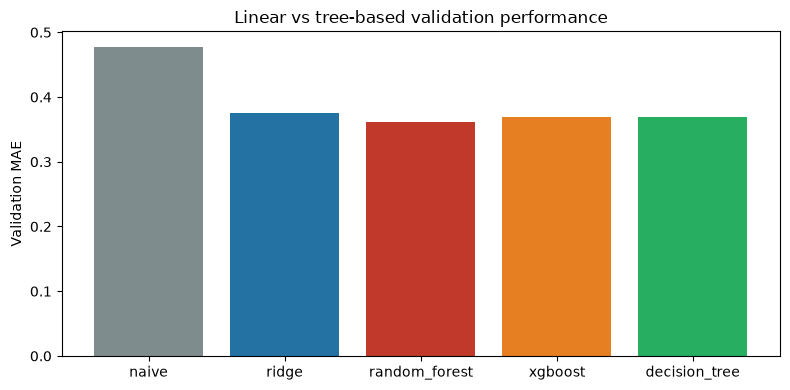

In [26]:
import matplotlib.pyplot as plt
import polars as pl

from perishable_demand_forecasting.config import FORECASTING_DIR

tree_metrics = pl.read_csv(
    FORECASTING_DIR / "tree_validation_metrics.csv"
).sort("mae")
ridge_metrics = pl.read_csv(FORECASTING_DIR / "ridge_validation_metrics.csv")
naive_metrics = pl.read_csv(FORECASTING_DIR / "naive_validation_metrics.csv")

comparison = pl.concat(
    [
        pl.DataFrame(
            {
                "model": ["naive"],
                "mae": [
                    naive_metrics.filter(
                        pl.col("evaluation_scope") == "overall"
                    )["mae"][0]
                ],
            }
        ),
        pl.DataFrame(
            {
                "model": ["ridge"],
                "mae": [
                    ridge_metrics.filter(
                        pl.col("evaluation_scope") == "overall"
                    )["mae"][0]
                ],
            }
        ),
        tree_metrics.group_by("model").agg(pl.col("mae").min()).sort("mae"),
    ]
)

plt.figure(figsize=(8, 4))
plt.bar(
    comparison["model"].to_list(),
    comparison["mae"].to_list(),
    color=["#7f8c8d", "#2471a3", "#c0392b", "#e67e22", "#27ae60"][
        : comparison.height
    ],
)
plt.ylabel("Validation MAE")
plt.title("Linear vs tree-based validation performance")
plt.tight_layout()
plt.show()


## 9. Final forecasting evaluation

The final evaluation uses the untouched chronological test partition. The Naive baseline, Ridge Regression, and the selected Random Forest are evaluated against the same target rows. Negative predictions are reported rather than silently clipped during evaluation.


### What this script does

**Inputs**

The untouched forecasting test partition and the trained Ridge and Random Forest artifacts.

**Processing**

Generates seven-day predictions for both models and compares them with the Naive baseline on exactly the same test rows.

**Outputs**

Saves overall and horizon-level test metrics, including MAE, RMSE, bias, and negative-prediction rate.

**Why this step matters**

Provides the final unbiased comparison between the forecasting approaches on data not used for model selection.


In [27]:
run_module("perishable_demand_forecasting.forecasting.evaluate_ridge_forecast_test")

$ uv run python -m perishable_demand_forecasting.forecasting.evaluate_ridge_forecast_test
FINAL TEST EVALUATION: NAIVE VS RIDGE REGRESSION

Loading Ridge model: models\forecasting\ridge_forecast.joblib
Ridge alpha: 1.0

Loading untouched test dataset...
Test rows: 4,200,000

Validating test features...

Preparing Ridge test features...

Generating Ridge predictions...
Ridge predictions generated successfully.

Evaluating Naive baseline...

Evaluating Ridge Regression...

OVERALL TEST RESULTS
shape: (2, 6)
┌───────────────┬──────────────┬──────────┬──────────┬───────────┬─────────────────────────┐
│ model         ┆ observations ┆ mae      ┆ rmse     ┆ bias      ┆ negative_prediction_pct │
│ ---           ┆ ---          ┆ ---      ┆ ---      ┆ ---       ┆ ---                     │
│ str           ┆ u32          ┆ f64      ┆ f64      ┆ f64       ┆ f64                     │
╞═══════════════╪══════════════╪══════════╪══════════╪═══════════╪═════════════════════════╡
│ naive         ┆ 420000

'===========================================================================\nFINAL TEST EVALUATION: NAIVE VS RIDGE REGRESSION\n===========================================================================\n\nLoading Ridge model: models\\forecasting\\ridge_forecast.joblib\nRidge alpha: 1.0\n\nLoading untouched test dataset...\nTest rows: 4,200,000\n\nValidating test features...\n\nPreparing Ridge test features...\n\nGenerating Ridge predictions...\nRidge predictions generated successfully.\n\nEvaluating Naive baseline...\n\nEvaluating Ridge Regression...\n\n===========================================================================\nOVERALL TEST RESULTS\n===========================================================================\nshape: (2, 6)\n┌───────────────┬──────────────┬──────────┬──────────┬───────────┬─────────────────────────┐\n│ model         ┆ observations ┆ mae      ┆ rmse     ┆ bias      ┆ negative_prediction_pct │\n│ ---           ┆ ---          ┆ ---      ┆ ---      ┆ --- 

### Tree model test evaluation

The tuned Random Forest (and, when present, the final full-data `train.py` artifact) is scored on the test partition with the same protocol.


In [28]:
run_module("perishable_demand_forecasting.forecasting.evaluate_tree_forecast_test")

$ uv run python -m perishable_demand_forecasting.forecasting.evaluate_tree_forecast_test
FINAL TEST EVALUATION: TUNED TREE MODEL

Loading tuned tree model: C:\Users\prite\repos\perishable-demand-forecasting\models\forecasting\final_demand_forecast.pkl
Family: random_forest
Params: {'n_estimators': 60, 'max_depth': 14, 'min_samples_leaf': 20, 'max_samples': 0.4, 'max_features': 0.5, 'n_jobs': 8, 'random_state': 42}

Loading untouched test dataset...
Test rows: 4,200,000

Validating test features...

Generating tree predictions...

Evaluating Naive baseline...
Evaluating tuned tree model...

OVERALL TEST RESULTS
        model  observations      mae     rmse      bias  negative_prediction_pct
        naive       4200000 0.512812 0.814507 -0.037006                      0.0
random_forest       4200000 0.399386 0.651719 -0.107226                      0.0

TEST RESULTS BY FORECAST HORIZON
        model  forecast_horizon  observations      mae     rmse      bias  negative_prediction_pct
      

"===========================================================================\nFINAL TEST EVALUATION: TUNED TREE MODEL\n===========================================================================\n\nLoading tuned tree model: C:\\Users\\prite\\repos\\perishable-demand-forecasting\\models\\forecasting\\final_demand_forecast.pkl\nFamily: random_forest\nParams: {'n_estimators': 60, 'max_depth': 14, 'min_samples_leaf': 20, 'max_samples': 0.4, 'max_features': 0.5, 'n_jobs': 8, 'random_state': 42}\n\nLoading untouched test dataset...\nTest rows: 4,200,000\n\nValidating test features...\n\nGenerating tree predictions...\n\nEvaluating Naive baseline...\nEvaluating tuned tree model...\n\n===========================================================================\nOVERALL TEST RESULTS\n===========================================================================\n        model  observations      mae     rmse      bias  negative_prediction_pct\n        naive       4200000 0.512812 0.814507 -0.037006 

### Final test results

| Model | MAE | RMSE | Bias | Negative predictions |
|---|---:|---:|---:|---:|
| Naive baseline | 0.512812 | 0.814507 | -0.037006 | 0.00% |
| Ridge Regression (alpha=1) | 0.407412 | 0.648432 | -0.114638 | 3.54% |
| Random Forest (final) | **0.399386** | 0.651719 | -0.107226 | 0.00% |

The selected Random Forest reduced test MAE by approximately 22.12% versus the Naive baseline and by approximately 1.97% versus Ridge. Ridge keeps a slightly lower RMSE (0.6484 vs 0.6517). Both models have a negative bias, and Random Forest avoids negative predictions entirely; these limitations are reported transparently.


## 10. Reproducibility and generated artifacts

The pipeline writes intermediate datasets, metrics, and model artifacts to the following locations:

- `data/processed/freshretailnet/recovery/`
- `data/processed/freshretailnet/features/`
- `data/processed/freshretailnet/forecasting/`
- `models/recovery/`
- `models/forecasting/`

The notebook calls the existing modules rather than duplicating their implementations. Run the cells from top to bottom in a clean project environment. Some stages process millions of rows and can require substantial memory and execution time.

For deployment, `train.py` fits the final Random Forest model on the train+validation partitions and saves it to `models/forecasting/final_demand_forecast.pkl`. `predict.py` loads that artifact and serves demand forecasts through a Flask API (`uv run python predict.py`).
